In [38]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import sys
sys.path.append(os.path.abspath(".."))   # one level up
import numpy as np
import cv2
import open3d as o3d
from scipy.spatial.transform import Rotation
from utils.lidar import PointCloud
from utils.camera import ImageData
import utils.utils as utils
from natsort import natsorted, index_natsorted
import torch
from tqdm import tqdm
import pickle

# Toggle the following boolean to False if not using HuggingFace App
hf_app = False

if hf_app:
    from huggingface_hub import snapshot_download

################## set device based on cuda availability #################
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print('CUDA availability: ' + str(torch.cuda.is_available()))

####################### Functions for matching using numpy on CPU or Pytorch on GPU ###################
def getMatchIndsCPU(ft_ref,ft_qry,topK=20,metric='cosine'):
    """
    metric: 'euclidean' or 'cosine'
    """
    # dMat = cdist(ft_ref,ft_qry,metric)

    ft_qry_norm = ft_qry / np.linalg.norm(ft_qry, axis=1, keepdims=True)  # Shape (M, N)
    ft_ref_norm = ft_ref / np.linalg.norm(ft_ref, axis=1, keepdims=True)  # Shape (C, N)

    # Step 2: Compute cosine similarity
    dMat = 1 - (ft_ref_norm @ ft_qry_norm.T)
    mInds = np.argsort(dMat,axis=0)[:topK].squeeze() # shape: K x ft_qry.shape[0]
    return mInds, dMat


def getMatchIndsGPU(ft_ref, ft_qry,topK=20, metric='cosine'):
    # metric: 'euclidean' or 'cosine'
    ft_qry_tensor = torch.Tensor(ft_qry).to(device)
    ft_ref_tensor = torch.Tensor(ft_ref).to(device)

    if metric == 'euclidean':
        # Use torch's cdist for Euclidean distance
        dMat = torch.cdist(ft_ref, ft_qry)
    
    elif metric == 'cosine':
        # # Normalize both the query and reference tensors
        ft_qry_norm = ft_qry_tensor / ft_qry_tensor.norm(dim=1, keepdim=True)
        ft_ref_norm = ft_ref_tensor / ft_ref_tensor.norm(dim=1, keepdim=True)
        # Compute cosine similarity (1 - cosine similarity for distance)
        dMat = 1 - ft_ref_norm @ ft_qry_norm.t()

    # Get the indices of the top 5 closest matches
    mInds = torch.argsort(dMat, dim=0)[:topK].squeeze()
    
    return mInds, dMat


CUDA availability: True


In [39]:
# qry_sets = [
#     'Cambogan_20250811_113017',
#     # 'DairyCreek_20250811_103318',
#     # 'Holmview_20250820_130327',
#     # 'Pullenvale_20250916_124105',
# ]

qry_sets = [
    'Cambogan_20250812_122101',
    # 'Dairy-Creek_20250812_123312',
    # 'Holmview_20250812_120856',
    # 'Pullenvale_20250812_134524',
]

ref_sets = [
    'Cambogan_20250812_122339',
    # 'Dairy-Creek_20250812_122954',
    # 'Holmview_20250812_120100',
    # 'Pullenvale_20250812_134316',
]

vpr_descs = [
    # 'cosplace',
    # 'boq',
    # 'clique-mining',
    # 'cricavpr',
    'eigenplaces',
    # 'mixvpr',
    # 'salad',
    # 'supervlad',
    # 'anyloc-urban',
]

# vpr_descs = [
#     'cosplace',
# ]

img_calib_file = f"../camera_calib.txt"

dist_tolerances = [1, 2, 4, 6, 8, 10]
# dist_tolerance = 10 # metres
# qry_idx = 4

# User parameters

In [40]:
################ Reference filenames and directories #################################
ref_condition = 'dry'
ref_camera_pos = 'front'

ref_timestamps = []
ref_utms = []
ref_img_filenames = []
ref_utm_filenames = []

for ref_set in ref_sets:
    print(f"Loading {ref_set}")
    ref_root_directory = f"D:/Datasets/FRED/{ref_condition}/KITTI-style"
    ref_vpr_root = f"D:/Datasets/FRED/vpr_ftrs/{ref_condition}/KITTI-style"

    ref_image_dir = f"{ref_root_directory}/{ref_set}/{ref_camera_pos}-imgs/"
    ref_utm_dir = f"{ref_root_directory}/{ref_set}/utm/"


    this_ref_timestamp = [filename.split('.png')[0] for filename in natsorted(os.listdir(ref_image_dir)) if os.path.isfile(ref_image_dir+filename)]
    ref_timestamps = ref_timestamps+this_ref_timestamp
    ref_utms = ref_utms+[np.loadtxt(ref_utm_dir+filename) for filename in natsorted(os.listdir(ref_utm_dir)) if os.path.isfile(ref_utm_dir+filename)]
    ref_utm_filenames = ref_utm_filenames+[utils.get_corr_files(ref_timestamp, [ref_utm_dir,]) for ref_timestamp in this_ref_timestamp]
    ref_img_filenames = ref_img_filenames+[filename for filename in natsorted(os.listdir(ref_image_dir)) if os.path.isfile(ref_image_dir+filename)]

ref_utms = np.array(ref_utms)

dMats = []
idxs = []

for vpr_desc in vpr_descs:

    print(f"Evaluating {vpr_desc} descriptors")

    all_results = []

    first = True

    print(f"Loading references")

    for ref_set in ref_sets:
        print(f"Loading {ref_set} {vpr_desc} descriptors")
        ref_root_directory = f"D:/Datasets/FRED/{ref_condition}/KITTI-style"
        ref_vpr_root = f"D:/Datasets/FRED/vpr_ftrs/{ref_condition}/KITTI-style"

        ref_image_dir = f"{ref_root_directory}/{ref_set}/{ref_camera_pos}-imgs/"

        ref_name_sort_idx = index_natsorted(os.listdir(ref_image_dir))
        ref_ftr = np.load(f"{ref_vpr_root}/{ref_set}/{vpr_desc}/queries_descriptors.npy")
        if first:
            ref_ftrs = ref_ftr[ref_name_sort_idx]
            first = False
        else:
            ref_ftrs = np.vstack((ref_ftrs, ref_ftr[ref_name_sort_idx]))


    for qry_set in qry_sets:

        print(f"Evaluating {qry_set}")

        ################ Query filenames and directories #################################
        # qry_condition = 'flooded'
        qry_condition = 'dry'
        qry_camera_pos = 'front'
        qry_root_directory = f"D:/Datasets/FRED/{qry_condition}/KITTI-style"
        qry_vpr_root = f"D:/Datasets/FRED/vpr_ftrs/{qry_condition}/KITTI-style"

        qry_image_dir = f"{qry_root_directory}/{qry_set}/{qry_camera_pos}-imgs/"
        qry_utm_dir = f"{qry_root_directory}/{qry_set}/utm/"
        qry_timestamps = [filename.split('.png')[0] for filename in natsorted(os.listdir(qry_image_dir)) if os.path.isfile(qry_image_dir+filename)]
        qry_name_sort_idx = index_natsorted(os.listdir(qry_image_dir))
        qry_ftrs = np.load(f"{qry_vpr_root}/{qry_set}/{vpr_desc}/queries_descriptors.npy")
        qry_ftrs = qry_ftrs[qry_name_sort_idx]

        mInds, dMat = getMatchIndsGPU(ref_ftrs,qry_ftrs,topK=1)

        # print(dMat.shape)
        dMat = dMat.cpu().numpy()

        # dMats.append(dMat.mean(axis=1).tolist())
        # idxs.append(np.arange(ref_ftr.shape[0]).tolist())

    #     mInds = mInds.cpu().numpy()
    #     # in_tol = []
    #     in_tols = {'1': [], '2': [], '4': [], '6': [], '8': [], '10': []}
    #     distss = {'1': [], '2': [], '4': [], '6': [], '8': [], '10': []}
    #     # dists = []
    #     # valid_qry = 0
    #     valid_qrys = {'1': 0, '2': 0, '4': 0, '6': 0, '8': 0, '10': 0}

    #     for qry_idx in tqdm(range(len(qry_timestamps))):

    #         qry_image_timestamp = qry_timestamps[qry_idx]
    #         qry_image_filename = f"{qry_image_dir}/{qry_image_timestamp}.png"
    #         qry_utm_timestamp = utils.get_corr_files(qry_image_timestamp, [qry_utm_dir,])
    #         qry_utm = np.loadtxt(qry_utm_timestamp)

    #         diffs = ref_utms - qry_utm           # shape (N, 2)
    #         qry_dists = np.linalg.norm(diffs, axis=1)   # shape (N,)

    #         for dist_tolerance in dist_tolerances:
    #             if qry_dists.min() > dist_tolerance:
    #                 continue
    #             else:
    #                 valid_qrys[str(dist_tolerance)] += 1

    #             ref_utm = np.loadtxt(ref_utm_filenames[int(mInds[qry_idx])])

    #             diff = ref_utm - qry_utm           # shape (N, 2)
    #             dist = np.linalg.norm(diff)   # shape (N,)
    #             distss[str(dist_tolerance)].append(dist)
    #             if dist < dist_tolerance:
    #                 # in_tol.append(1)
    #                 in_tols[str(dist_tolerance)].append(1)
    #             else:
    #                 # in_tol.append(0)
    #                 in_tols[str(dist_tolerance)].append(0)

    #         # qry_image = ImageData(qry_image_filename, img_calib_file)

    #         # fig, ax = plt.subplots(1, 2, figsize=(19.4, 6))
    #         # ax[0].clear()
    #         # ax[1].clear()

    #         # ax[0].imshow(qry_image.image[:, :, ::-1])
    #         # ax[0].set_title(f"{qry_image_timestamp}.png")
    #         # ax[0].axis("off")

    #         # # Show matching reference image
    #         # # ref_img_timestamp = utils.get_corr_files(ref_timestamps[int(mInds[qry_idx])], [ref_image_dir,])
    #         # ref_image = ImageData(f"{ref_image_dir}/{ref_timestamps[int(mInds[qry_idx])]}.png", img_calib_file)
    #         # ax[1].imshow(ref_image.image[:, :, ::-1])
    #         # ax[1].set_title(f"{ref_timestamps[int(mInds[qry_idx])]}\nDist={dist:.2f}m")

    #         # ax[1].axis("off")
    #         # fig.canvas.draw()

    #     # print(f"Recall for {qry_set} using {vpr_desc}: {np.sum(np.array(in_tol))/valid_qry:.02%}")
    #     # all_results.append(np.sum(np.array(in_tol))/valid_qry)
    #     with open(f"{qry_vpr_root}/{qry_set}/{vpr_desc}/in_tols.pkl", 'wb') as file:
    #         pickle.dump(in_tols, file)
    #     with open(f"{qry_vpr_root}/{qry_set}/{vpr_desc}/distss.pkl", 'wb') as file:
    #         pickle.dump(distss, file)
    #     with open(f"{qry_vpr_root}/{qry_set}/{vpr_desc}/valid_qrys.pkl", 'wb') as file:
    #         pickle.dump(valid_qrys, file)
    #     # plt.figure()
    #     # plt.plot(np.clip(dists, 0, 30))
    #     # plt.ylim((0,35))
    
    # # print(f"All {vpr_desc} results:")
    # # print(all_results)

Loading Cambogan_20250812_122339
Evaluating eigenplaces descriptors
Loading references
Loading Cambogan_20250812_122339 eigenplaces descriptors
Evaluating Cambogan_20250812_122101


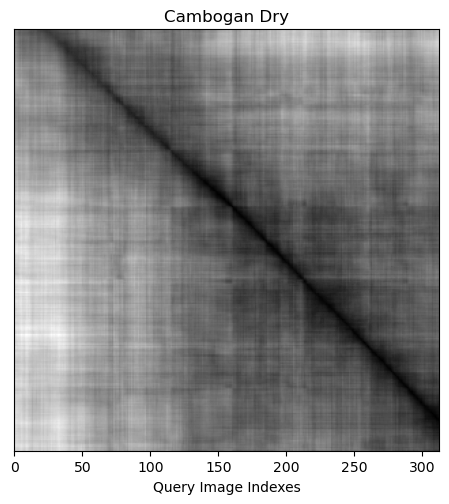

In [42]:
# dMats = np.array(dMats)
# idxs = np.array(idxs)
# plt.figure()
# for idx in range(len(dMats)):
#     plt.scatter(idxs[idx, :], dMats[idx, :])
plt.figure()
plt.imshow(dMat, cmap='gray')
plt.tight_layout()
plt.xlabel('Query Image Indexes')
# plt.ylabel('Reference Image Indexes')
plt.yticks([])
plt.title('Cambogan Dry')
plt.savefig(f"{qry_vpr_root}/{qry_set}/{vpr_desc}_dMat.pdf", format='PDF', dpi=300, bbox_inches='tight')